# PPE Detection System — Model Evaluation

This notebook evaluates the immutable **YOLOv8n baseline** trained for 50 epochs on `PPE-4Class-Resized`. It will grow section-by-section so that each evaluation result is understood before it is used to guide Phase 6.

**Current scope:** complete Phase 5 evaluation of the immutable baseline.

> **Notebook execution:** Jupyter saves displayed outputs but not live Python variables. After reopening the notebook or restarting its kernel, use **Restart Kernel and Run All Cells** so objects such as `Path`, `model`, and `metrics` are recreated in order.

## 1. Imports and runtime configuration

We keep the first imports small and purposeful:

- `Path` builds operating-system-safe paths instead of fragile string paths.
- `sys` tells us which Python executable the notebook kernel is actually using. This catches a common VS Code mistake: selecting a global interpreter instead of the project `.venv`.
- `torch` reports CUDA availability and provides the device choice used by later evaluation cells.
- `ultralytics` exposes its installed version, while `YOLO` is the Python API used to load and evaluate the detector.

In [1]:
from pathlib import Path
import sys

import torch
import ultralytics
from ultralytics import YOLO

DEVICE = 0 if torch.cuda.is_available() else "cpu"

print(f"Python executable: {sys.executable}")
print(f"Python version: {sys.version.split()[0]}")
print(f"Ultralytics version: {ultralytics.__version__}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(DEVICE)}")
else:
    print("CUDA device: CPU fallback")

Python executable: c:\Users\Shreyas\Documents\ppe-detection-system\.venv\Scripts\python.exe
Python version: 3.14.0
Ultralytics version: 8.4.87
PyTorch version: 2.11.0+cu128
CUDA available: True
CUDA device: NVIDIA GeForce RTX 5050 Laptop GPU


## 2. Resolve project paths robustly

A notebook may start with either the repository root or `notebooks/` as its working directory. A path such as `runs/train/.../best.pt` therefore works in one case and fails in the other.

`find_project_root` starts at the current working directory and walks upward until it finds three repository markers. Every other path is then derived from that single root. This makes the notebook independent of the directory from which VS Code launches its kernel.

The checks fail early with a clear message if an artifact is moved or missing. The legacy nested prediction directory is recorded as it exists today; we do not need to fix its naming to evaluate its contents.

In [2]:
def find_project_root(start: Path | None = None) -> Path:
    """Find the repository root from either the root or a child directory."""
    current = (start or Path.cwd()).resolve()
    markers = ("requirements.txt", "dataset", "runs")

    for candidate in (current, *current.parents):
        if all((candidate / marker).exists() for marker in markers):
            return candidate

    raise FileNotFoundError(
        f"Could not find the project root from {current}. "
        f"Expected these markers: {markers}"
    )


PROJECT_ROOT = find_project_root()
TRAIN_RUN_DIR = PROJECT_ROOT / "runs" / "train" / "ppe4_resized_yolov8n"
MODEL_PATH = TRAIN_RUN_DIR / "weights" / "best.pt"
DATASET_DIR = PROJECT_ROOT / "dataset" / "PPE-4Class-Resized"
DATA_YAML = DATASET_DIR / "data.yaml"
UNSEEN_IMAGES_DIR = PROJECT_ROOT / "outputs" / "unseen_images"
PREDICTION_OUTPUT_DIR = (
    PROJECT_ROOT / "runs" / "detect" / "runs" / "predict" / "phase5_unseen"
)

ARTIFACTS = {
    "trained weights": MODEL_PATH,
    "dataset configuration": DATA_YAML,
    "resized dataset": DATASET_DIR,
    "unseen images": UNSEEN_IMAGES_DIR,
    "existing prediction outputs": PREDICTION_OUTPUT_DIR,
}

missing_artifacts = [name for name, path in ARTIFACTS.items() if not path.exists()]
if missing_artifacts:
    missing_details = "\n".join(
        f"- {name}: {ARTIFACTS[name]}" for name in missing_artifacts
    )
    raise FileNotFoundError(f"Required project artifacts are missing:\n{missing_details}")

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}
unseen_image_paths = sorted(
    path
    for path in UNSEEN_IMAGES_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
)
prediction_image_paths = sorted(
    path
    for path in PREDICTION_OUTPUT_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
)

print(f"Notebook working directory: {Path.cwd().resolve()}")
print(f"Project root: {PROJECT_ROOT}")
for name, path in ARTIFACTS.items():
    print(f"{name}: {path.relative_to(PROJECT_ROOT)}")
print(f"Unseen source images found: {len(unseen_image_paths)}")
print(f"Existing prediction images found: {len(prediction_image_paths)}")

Notebook working directory: C:\Users\Shreyas\Documents\ppe-detection-system\notebooks
Project root: C:\Users\Shreyas\Documents\ppe-detection-system
trained weights: runs\train\ppe4_resized_yolov8n\weights\best.pt
dataset configuration: dataset\PPE-4Class-Resized\data.yaml
resized dataset: dataset\PPE-4Class-Resized
unseen images: outputs\unseen_images
existing prediction outputs: runs\detect\runs\predict\phase5_unseen
Unseen source images found: 10
Existing prediction images found: 10


## 3. Load the trained baseline

`YOLO(MODEL_PATH)` reconstructs the detector architecture and loads the learned parameters stored in `best.pt`. The returned `model` is an Ultralytics `YOLO` wrapper: later we will call methods such as `model.val(...)` for quantitative evaluation and `model.predict(...)` for unseen-image inference.

Loading is not the same as evaluation. This cell performs no forward pass over the validation set and does not create prediction output. We also verify the task and class-name order immediately, because evaluating the wrong checkpoint can otherwise produce plausible-looking but meaningless results.

In [3]:
model = YOLO(str(MODEL_PATH))

EXPECTED_CLASS_NAMES = [
    "person",
    "helmet",
    "safety-vest",
    "face-mask-medical",
]
loaded_class_names = [model.names[index] for index in sorted(model.names)]

if model.task != "detect":
    raise ValueError(f"Expected a detection model, but loaded task={model.task!r}")
if loaded_class_names != EXPECTED_CLASS_NAMES:
    raise ValueError(
        "Checkpoint class names do not match the PPE-4Class definition. "
        f"Expected {EXPECTED_CLASS_NAMES}, loaded {loaded_class_names}."
    )

print(f"Model task: {model.task}")
print(f"Classes ({len(loaded_class_names)}): {loaded_class_names}")
print(f"Selected evaluation device: {DEVICE}")

Model task: detect
Classes (4): ['person', 'helmet', 'safety-vest', 'face-mask-medical']
Selected evaluation device: 0


### Setup checkpoint

After running the cells above, verify that:

1. `Python executable` points to this repository's `.venv`.
2. CUDA is available and the RTX 5050 is shown.
3. All five artifact paths are printed without an exception.
4. Both image counts are 10.
5. The loaded task is `detect` and the four classes appear in the expected order.

With those checks confirmed, the baseline is ready for controlled validation.

## 4. Run controlled validation

Validation measures the frozen checkpoint on the labeled validation split. It does **not** update weights, run backpropagation, or continue training.

The important arguments below are:

- `data`: the dataset YAML that defines the validation images and the class mapping.
- `split="val"`: evaluates only the validation split.
- `imgsz=640`: matches the baseline training image size, keeping this comparison controlled.
- `batch=16`: matches the baseline batch size. It affects throughput and memory use, not the learned weights.
- `device=DEVICE`: uses GPU 0 when CUDA is available and otherwise falls back to CPU.
- `plots=True`: produces the confusion matrix and PR/F1-related plots needed later in this notebook.
- `project` and `name`: place artifacts in one explicit directory instead of relying on Ultralytics' default output path.
- `exist_ok=True`: reuses that evaluation directory when the cell is rerun, preventing `...2`, `...3`, and similar duplicate runs.

We intentionally do not set a normal inference confidence such as `0.25`. During validation, Ultralytics needs predictions across a wide confidence range to construct complete precision–recall curves and calculate AP.

In [4]:
VALIDATION_OUTPUT_DIR = PROJECT_ROOT / "runs" / "val"

metrics = model.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=640,
    batch=16,
    device=DEVICE,
    workers=4,
    plots=True,
    project=str(VALIDATION_OUTPUT_DIR),
    name="ppe4_resized_yolov8n_baseline",
    exist_ok=True,
)

Ultralytics 8.4.87  Python-3.14.0 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5050 Laptop GPU, 8123MiB)
Model summary (fused): 73 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 160.668.6 MB/s, size: 205.1 KB)
val: Scanning C:\Users\Shreyas\Documents\ppe-detection-system\dataset\PPE-4Class-Resized\valid\labels.cache... 1523 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1523/1523 336.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 96/96 13.1it/s 7.3s0.1s
                   all       1523       3136      0.761      0.631      0.681      0.459
                person       1515       2734      0.892      0.864      0.901      0.713
                helmet         93        154      0.734       0.61      0.651      0.473
           safety-vest         45         97      0.572      0.413      0.478       0.28
     face-mask-medical         75        151      0.

### Inspect the returned metrics object

`model.val(...)` returns an Ultralytics `DetMetrics` object. It contains numeric results, per-class statistics, speed measurements, and the directory containing generated plots. The bounding-box metrics are grouped under `metrics.box`:

- `mp`: mean precision across classes at Ultralytics' selected operating point.
- `mr`: mean recall across classes at that operating point.
- `map50`: mean Average Precision using IoU 0.50.
- `map`: COCO-style mean AP averaged over IoU thresholds 0.50 through 0.95. This is the stricter localization metric commonly written as mAP50–95.

Precision and recall describe one selected confidence operating point. AP instead summarizes the precision–recall curve over many confidence thresholds, so it is not tied to just one deployment threshold.

In [5]:
overall_metrics = {
    "Precision": float(metrics.box.mp),
    "Recall": float(metrics.box.mr),
    "mAP50": float(metrics.box.map50),
    "mAP50-95": float(metrics.box.map),
}

print(f"Metrics object: {type(metrics).__name__}")
print(f"Validation artifacts: {metrics.save_dir}")
for metric_name, value in overall_metrics.items():
    print(f"{metric_name:>9}: {value:.3f}")

Metrics object: DetMetrics
Validation artifacts: C:\Users\Shreyas\Documents\ppe-detection-system\runs\val\ppe4_resized_yolov8n_baseline
Precision: 0.761
   Recall: 0.631
    mAP50: 0.681
 mAP50-95: 0.459


### Validation checkpoint

The expected approximate baseline values are precision `0.759`, recall `0.631`, mAP50 `0.681`, and mAP50–95 `0.459`. Small differences in the last few decimal places can occur across library versions, but a large difference means we should stop and check the checkpoint, dataset, split, and evaluation settings.

After confirming these results, the next section extracts **per-class** metrics. That is essential because the overall mean can hide weak performance for an individual PPE class.

## 5. Extract per-class metrics

An overall mAP is a mean across classes. Because the validation set contains far more person instances than PPE instances, we must inspect each class rather than treating one overall number as the complete result.

`metrics.summary()` returns a `list` of dictionaries—one record per evaluated class. Ultralytics uses its stored AP-class indices to attach every metric row to the correct class name. This is safer than assuming that an arbitrary dictionary or array order matches class IDs.

Each record includes:

- `Images`: validation images containing at least one ground-truth instance of that class.
- `Instances`: total ground-truth objects of that class.
- precision, recall, and F1 at the selected operating point.
- mAP50 and the stricter mAP50–95.

We convert the records to a pandas `DataFrame` only for analysis and presentation; the underlying evaluation values still come from `DetMetrics`.

In [6]:
import pandas as pd

per_class_records = metrics.summary(normalize=True, decimals=5)
per_class_metrics = (
    pd.DataFrame(per_class_records)
    .rename(
        columns={
            "Box-P": "Precision",
            "Box-R": "Recall",
            "Box-F1": "F1",
        }
    )
    .set_index("Class")
)

missing_classes = set(EXPECTED_CLASS_NAMES) - set(per_class_metrics.index)
if missing_classes:
    raise ValueError(f"Validation metrics are missing classes: {sorted(missing_classes)}")

per_class_metrics.style.format(
    {
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1": "{:.3f}",
        "mAP50": "{:.3f}",
        "mAP50-95": "{:.3f}",
    }
)

,Images,Instances,Precision,Recall,F1,mAP50,mAP50-95
Class,,,,,,,
person,1515,2734,0.892,0.864,0.878,0.901,0.713
helmet,93,154,0.734,0.610,0.666,0.651,0.473
safety-vest,45,97,0.572,0.413,0.480,0.478,0.280
face-mask-medical,75,151,0.844,0.636,0.725,0.695,0.372


### Compare detection and localization quality

mAP50 accepts a predicted box when its IoU with the ground-truth box is at least 0.50. mAP50–95 repeats the AP calculation at increasingly strict IoU thresholds and averages the results.

The difference `mAP50 - mAP50-95` is therefore a useful diagnostic signal. A large gap suggests that the model can often find the object at a loose overlap threshold but struggles to place consistently tight bounding boxes. It is not a formal metric and does not prove the cause; object size, occlusion, ambiguous boundaries, and annotation consistency must be inspected later.

In [7]:
class_comparison = per_class_metrics[
    ["Images", "Instances", "Precision", "Recall", "mAP50", "mAP50-95"]
].copy()
class_comparison["mAP gap"] = (
    class_comparison["mAP50"] - class_comparison["mAP50-95"]
)
class_comparison = class_comparison.sort_values("mAP50-95", ascending=False)

class_comparison.style.format(
    {
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "mAP50": "{:.3f}",
        "mAP50-95": "{:.3f}",
        "mAP gap": "{:.3f}",
    }
)

,Images,Instances,Precision,Recall,mAP50,mAP50-95,mAP gap
Class,,,,,,,
person,1515,2734,0.892,0.864,0.901,0.713,0.188
helmet,93,154,0.734,0.610,0.651,0.473,0.178
face-mask-medical,75,151,0.844,0.636,0.695,0.372,0.323
safety-vest,45,97,0.572,0.413,0.478,0.280,0.198


### Per-class checkpoint

Use the two tables to answer these before drawing conclusions:

1. Which class has the lowest recall?
2. Which class has the lowest mAP50–95?
3. Which class has the largest gap between mAP50 and mAP50–95?
4. Do the instance counts establish that class imbalance caused the weaker result, or only support it as a hypothesis?

The tables identify **where** performance is weak. The confusion matrix and qualitative failure inspection will help explain **how** and **why** it is weak.

### Evidence-based interpretation

From this validation run:

- **Safety vest is the weakest class:** recall is `0.413`, mAP50 is `0.478`, and mAP50–95 is `0.280`. Low recall means many labeled vests are not being detected at the selected operating point.
- **Face mask has the largest mAP gap:** `0.695 - 0.372 = 0.323`. The detector can often find masks at IoU 0.50, but performance drops sharply when tighter localization is required.
- **Person is the strongest class:** it leads every reported quality metric and has far more validation examples.
- **Helmet is intermediate:** substantially weaker than person, but stronger than safety vest.

The validation set contains only 97 safety-vest instances across 45 images, compared with 2,734 person instances across 1,515 images. This supports class imbalance as a plausible contributor, but does not establish causation. Vest size, occlusion, visual diversity, annotation consistency, and scene context remain competing explanations that require image-level inspection.

## 6. Inspect the confusion matrix

For this Ultralytics detection matrix, **columns are true classes** and **rows are predicted classes**. Unlike a simple classification matrix, it includes a `background` row and column because object detection must also account for unmatched boxes.

Read it as follows:

- A class-to-same-class diagonal cell is a correctly matched detection.
- The `background` row under a true class represents false negatives: labeled objects the model missed.
- A predicted-class row under the `background` column represents false positives: predictions without a matching ground-truth object.
- Other off-diagonal cells represent class confusion, such as a true vest predicted as a person.

The raw matrix is useful for absolute counts, but person dominates those counts. The normalized matrix makes class-wise rates easier to compare. It is normalized by true-class columns, so each non-background true-class column is interpreted vertically.

Normalized confusion matrix


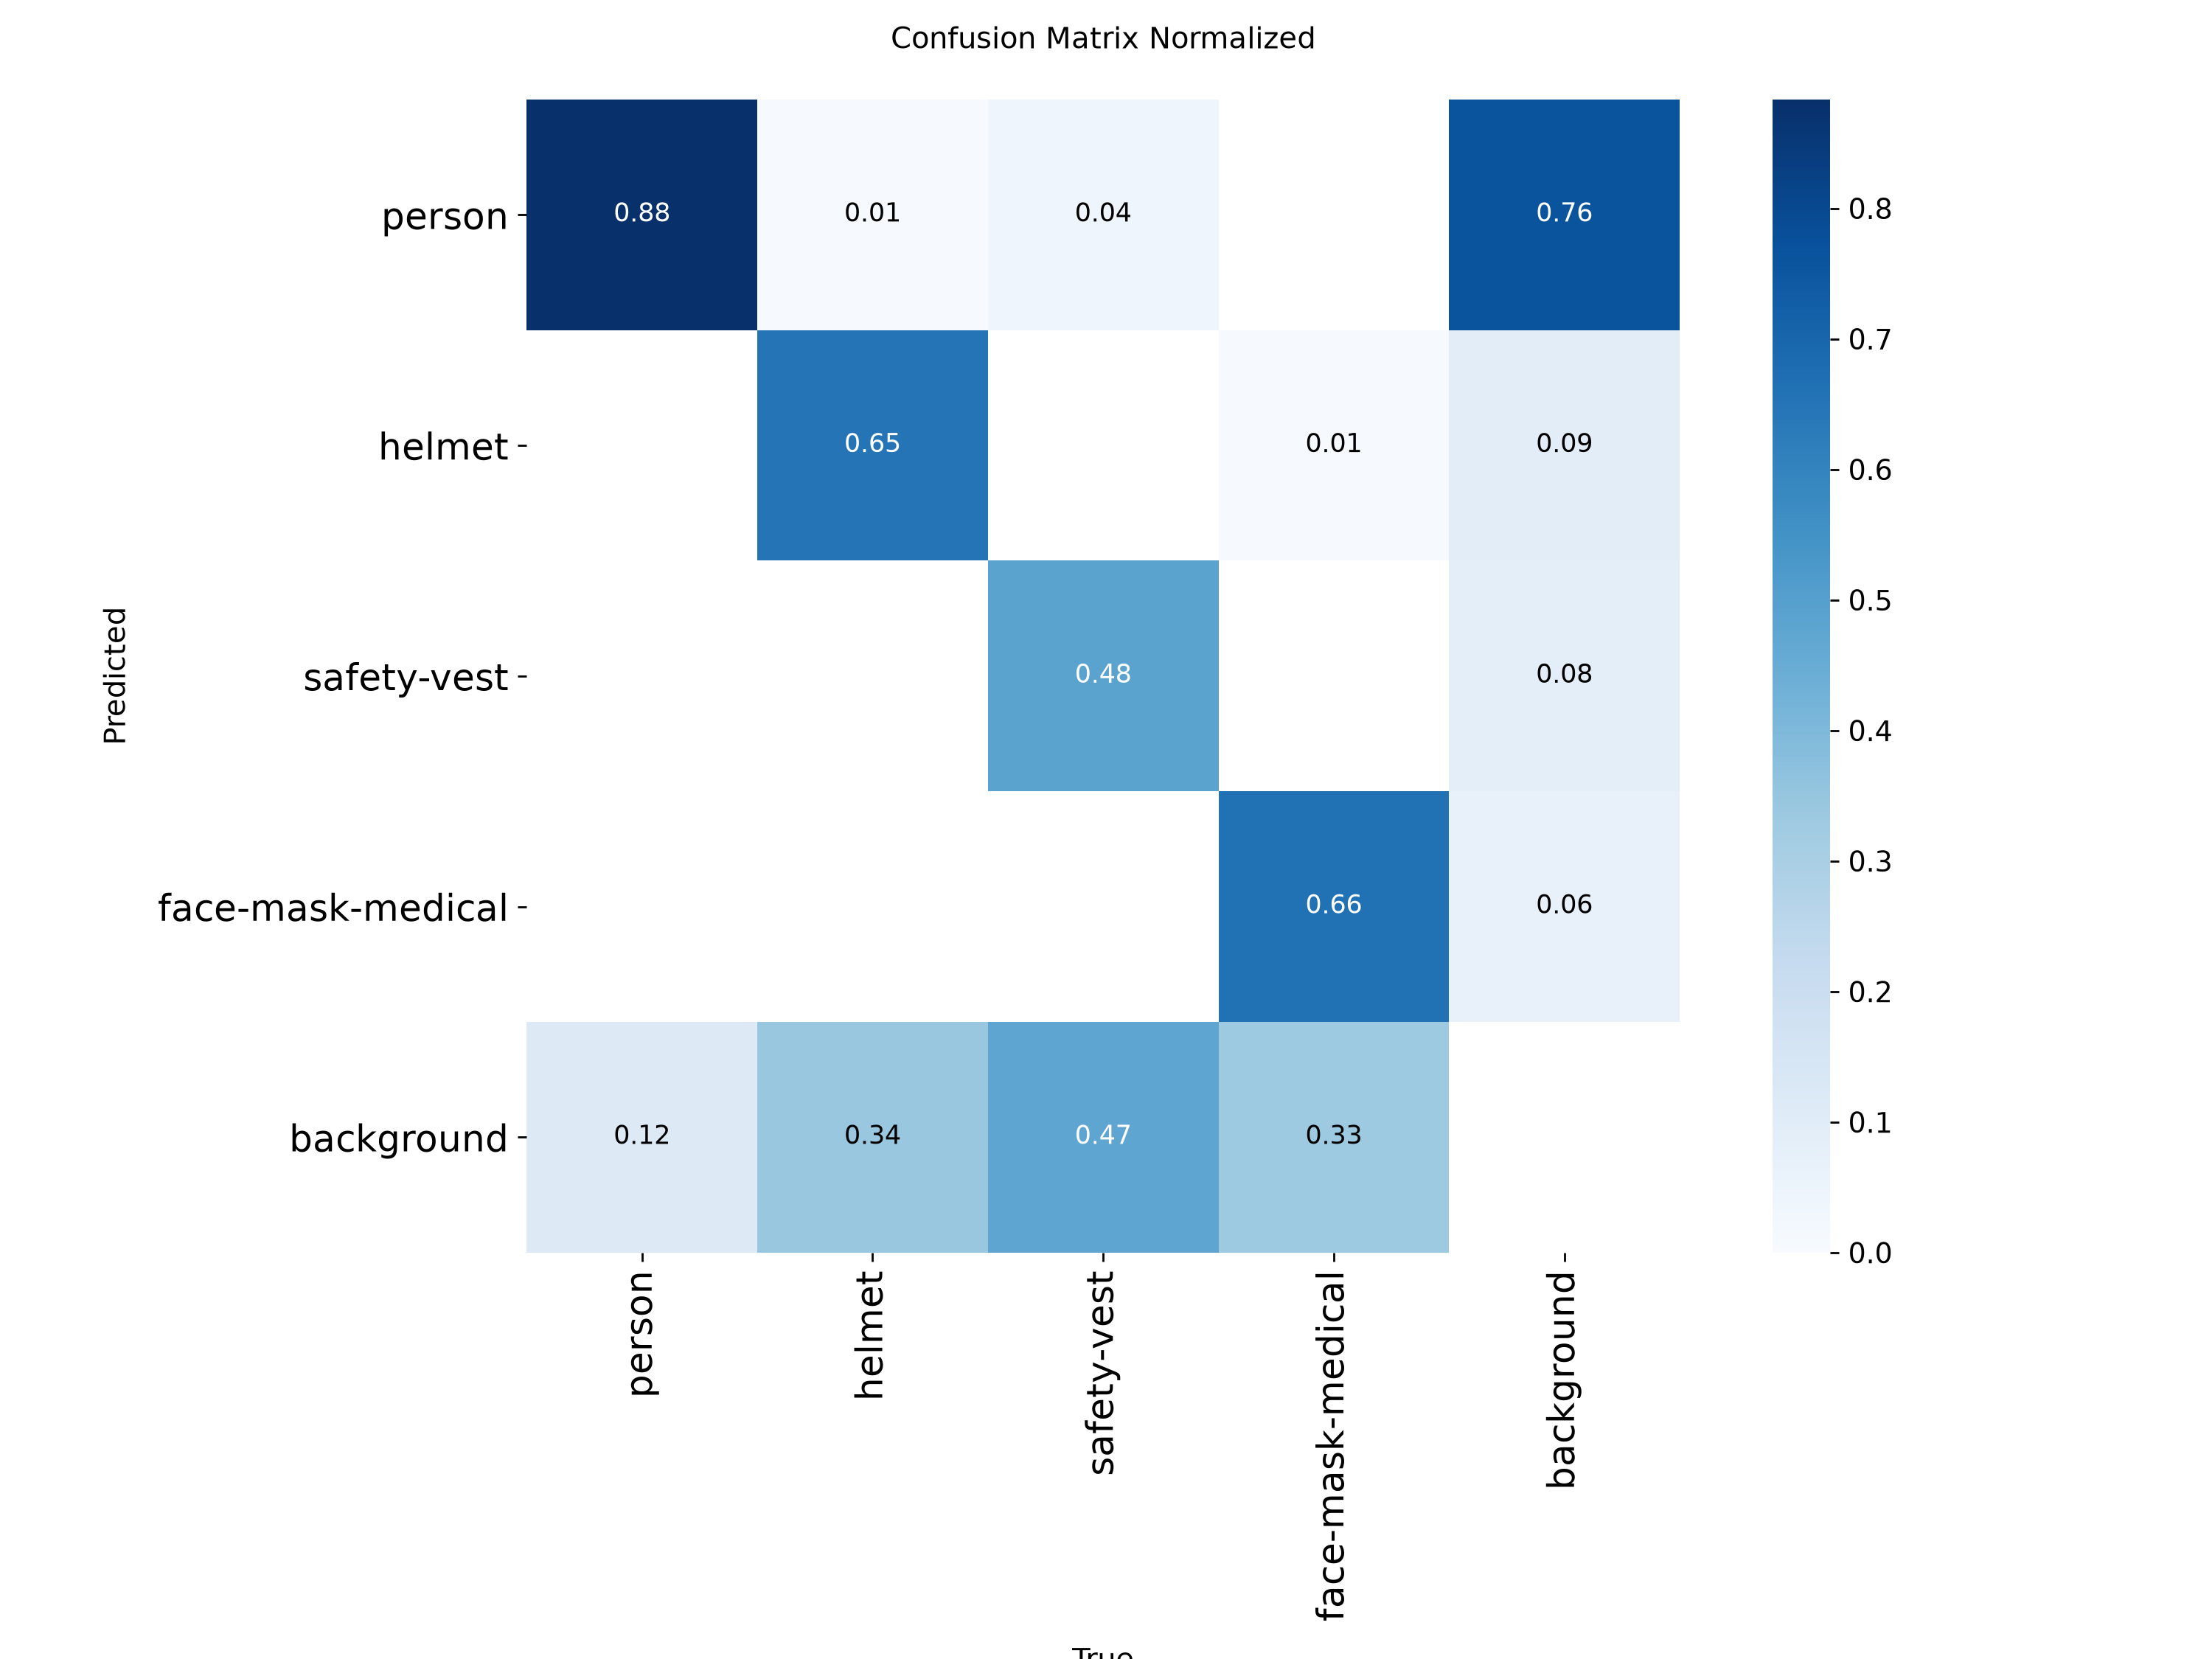

Raw-count confusion matrix


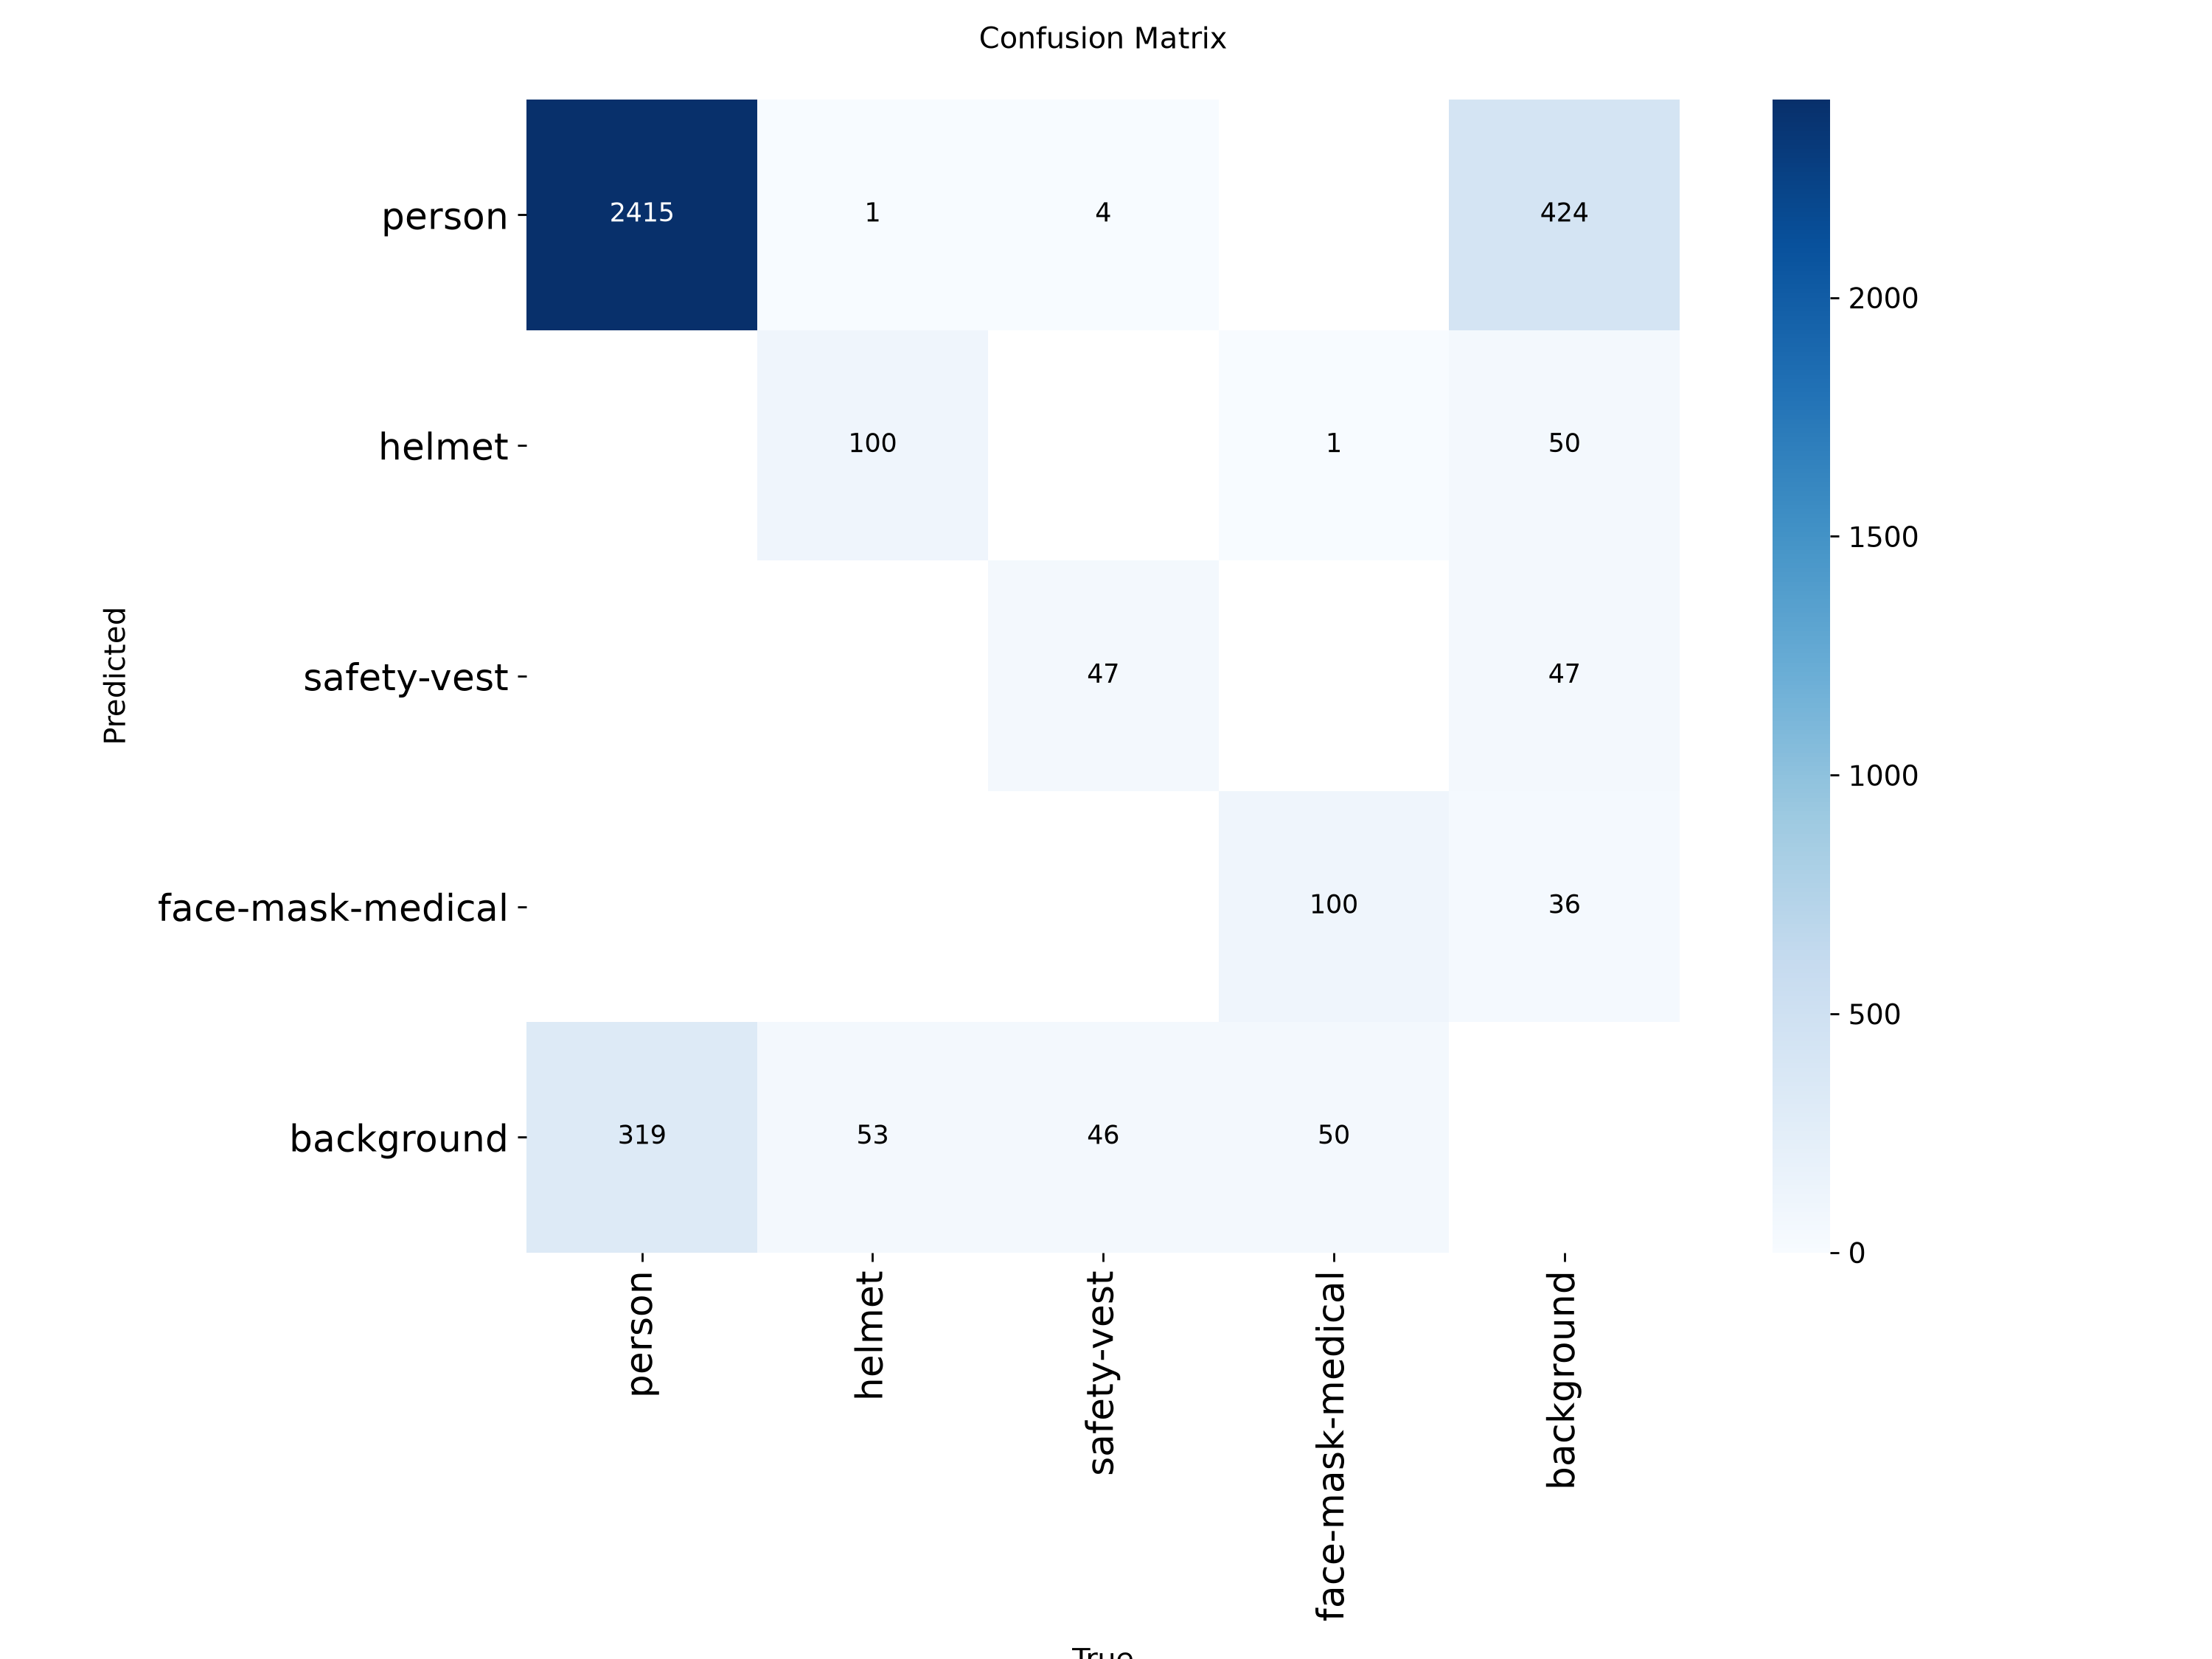

In [8]:
from IPython.display import display
from PIL import Image as PILImage

confusion_matrix_paths = {
    "Normalized confusion matrix": Path(metrics.save_dir)
    / "confusion_matrix_normalized.png",
    "Raw-count confusion matrix": Path(metrics.save_dir) / "confusion_matrix.png",
}

missing_matrices = [
    path for path in confusion_matrix_paths.values() if not path.is_file()
]
if missing_matrices:
    raise FileNotFoundError(
        "Missing confusion-matrix output(s):\n"
        + "\n".join(f"- {path}" for path in missing_matrices)
    )

for title, path in confusion_matrix_paths.items():
    print(title)
    with PILImage.open(path) as image:
        display(image.copy())

### What this matrix shows

Reading down each true-class column in the normalized matrix:

- **Person:** `0.88` is matched correctly and `0.12` falls into the background row.
- **Helmet:** `0.65` is matched correctly and `0.34` falls into background.
- **Safety vest:** only `0.48` is matched correctly, while `0.47` falls into background. This indicates that missed vests are a much larger issue than vest-to-another-PPE-class confusion.
- **Face mask:** `0.66` is matched correctly and `0.33` falls into background.

Most non-background off-diagonal cells are near zero, so the main class-wise problem is **failure to detect an object**, rather than repeatedly assigning one PPE label to another.

In the background column, `0.76` for person means 76% of the false-positive detections represented by that column are person predictions. It does **not** mean that 76% of all person predictions are false. The raw matrix shows the corresponding false-positive counts: 424 person, 50 helmet, 47 safety vest, and 36 face mask.

Finally, confusion-matrix values depend on the confidence and IoU matching rules used to build the matrix. They should support—not replace—the precision, recall, and AP metrics.

### Confusion-matrix checkpoint

The matrix strengthens one specific conclusion: safety-vest performance is recall-limited, with many true vests becoming background rather than another PPE class. It still cannot tell us whether those misses are caused by small objects, occlusion, unusual viewpoints, weak visual diversity, or annotation problems. Those causes require inspecting actual images and predictions.

Next, we inspect the precision–recall curve to understand performance across confidence thresholds rather than at only one operating point.

## 7. Inspect precision–recall behavior

A precision–recall (PR) curve shows the trade-off produced as the confidence threshold changes:

- The x-axis is recall: the fraction of labeled objects detected.
- The y-axis is precision: the fraction of retained predictions that are correct.
- High confidence thresholds usually keep fewer, more reliable predictions, giving higher precision but lower recall.
- Lowering the threshold admits more predictions, usually increasing recall while also introducing false positives and reducing precision.

A stronger detector keeps its curve closer to the top-right corner. The area under each class curve at IoU 0.50 is that class's AP50, shown in the legend. The thick blue curve is the mean behavior across classes, and its legend reports overall mAP50.

Importantly, the x-axis is recall—not confidence. This plot compares detector quality across operating points, but it does not directly tell us which numeric confidence threshold produced a point. We will use the confidence-based curves for that later.

Mean of the four class AP50 values: 0.681
DetMetrics overall mAP50:          0.681


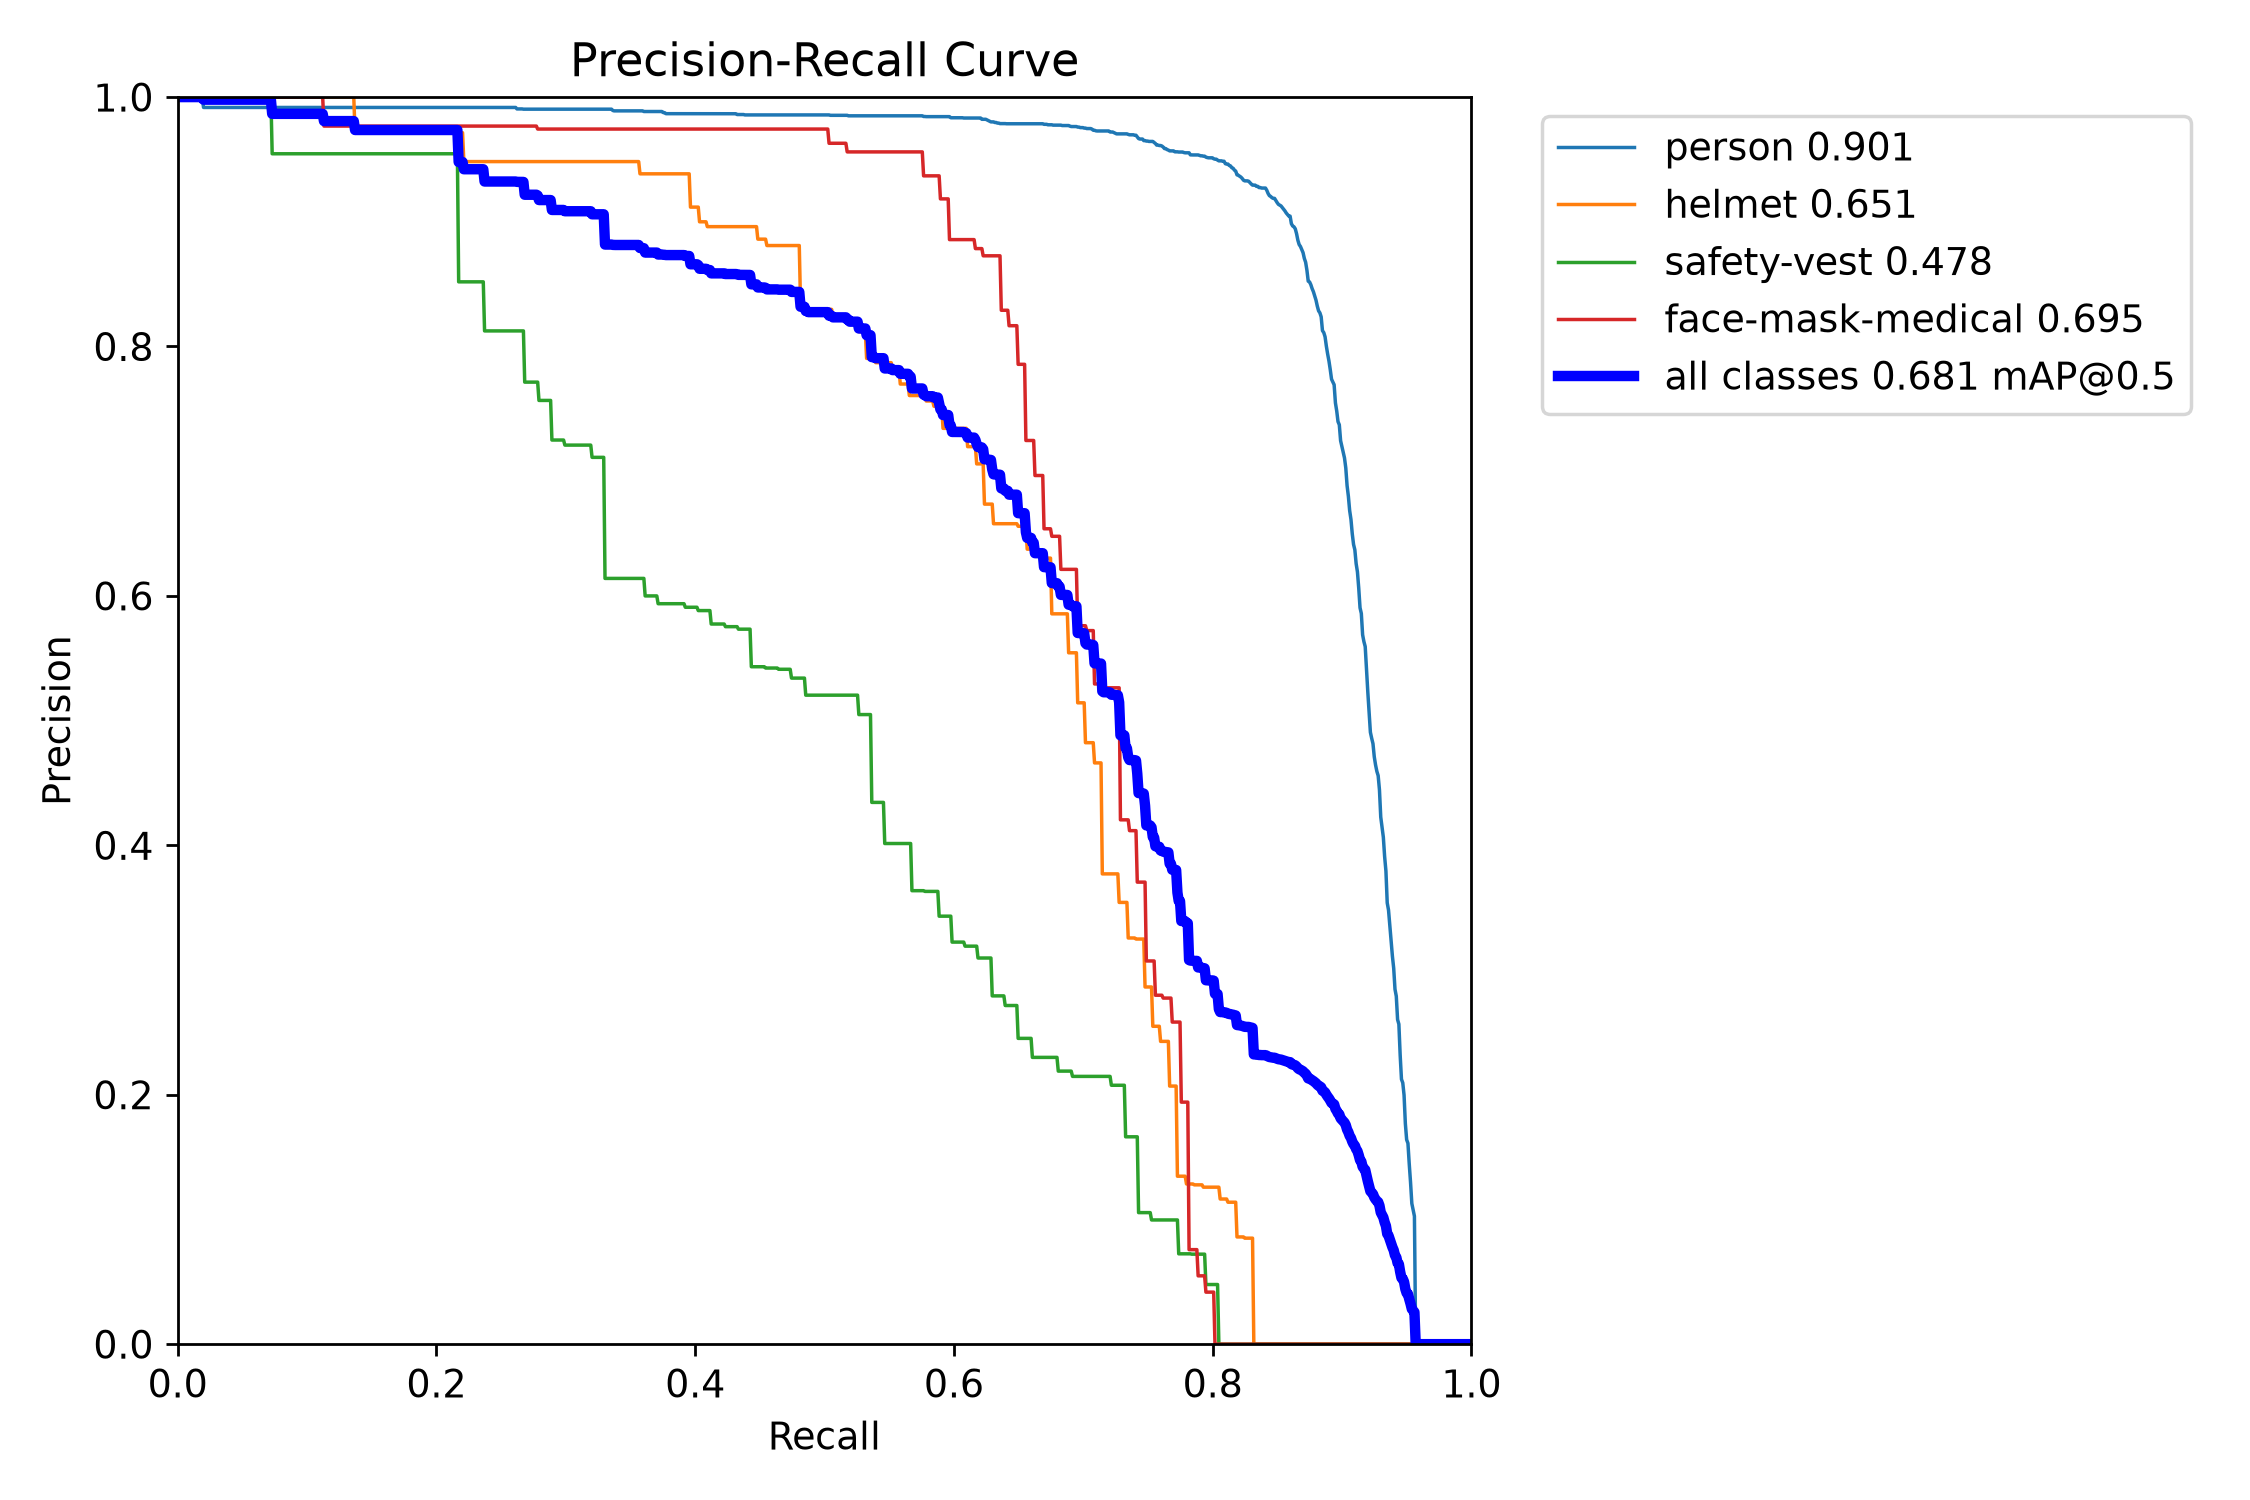

In [9]:
PR_CURVE_PATH = Path(metrics.save_dir) / "BoxPR_curve.png"
if not PR_CURVE_PATH.is_file():
    raise FileNotFoundError(f"Missing precision–recall curve: {PR_CURVE_PATH}")

mean_class_ap50 = float(per_class_metrics["mAP50"].mean())
print(f"Mean of the four class AP50 values: {mean_class_ap50:.3f}")
print(f"DetMetrics overall mAP50:          {metrics.box.map50:.3f}")

with PILImage.open(PR_CURVE_PATH) as image:
    display(image.copy())

### What this PR curve shows

- **Person (`AP50 = 0.901`)** stays close to the top boundary across most of the recall range. The detector ranks person predictions well and can retain both high precision and high recall.
- **Safety vest (`AP50 = 0.478`)** has the smallest area. Precision begins degrading much earlier as we try to recover more true vests, confirming that the weak result is not an artifact of one chosen confidence threshold.
- **Face mask (`AP50 = 0.695`)** maintains very high precision through a moderate recall range, then drops sharply as recall is pushed higher. This is consistent with a model that is reliable on its strongest mask detections but misses or poorly ranks harder masks.
- **Helmet (`AP50 = 0.651`)** is between face mask and safety vest, with a more gradual loss of precision.

The four class AP50 values average to the overall `0.681`. This is an **unweighted class mean**: safety vest contributes one quarter of mAP50 even though it has far fewer instances than person. That is useful because a weak PPE class cannot be hidden merely by the large number of person boxes.

The safety-vest curve is also more stepped and irregular. Its smaller validation sample—97 instances—can make the curve less stable, but the curve alone cannot distinguish limited data from difficult visuals or annotation issues.

### PR-curve checkpoint

The PR curve confirms that safety-vest weakness persists across confidence thresholds. Simply choosing a different global threshold cannot make its underlying AP equal to the stronger classes; it only changes the balance between its false positives and false negatives.

For a safety application we may eventually prefer an operating point with higher PPE recall, accepting some additional false alarms. We should not choose that threshold yet. The next section inspects F1, precision, and recall as explicit functions of confidence.

## 8. Inspect F1, precision, and recall versus confidence

Unlike the PR curve, these plots put the **confidence threshold directly on the x-axis**. They answer a deployment-oriented question: what happens to retained detections as we demand more confidence?

- Precision generally rises with confidence because uncertain predictions are removed.
- Recall generally falls because some true objects also have confidence below the threshold.
- F1 is the harmonic mean `2 × precision × recall / (precision + recall)`. It peaks where precision and recall are most balanced.

The thick blue F1 curve reaches approximately `0.69` at confidence `0.358`. That is the threshold maximizing **mean F1 across the four classes** on this validation set. It is a useful reference, not automatically the correct safety-system threshold: missing PPE may be more costly than generating an extra review alert.

In [10]:
import numpy as np
from ultralytics.utils.metrics import smooth

curve_lookup = {
    (x_label, y_label): (np.asarray(x_values), np.asarray(y_values))
    for x_values, y_values, x_label, y_label in metrics.curves_results
}
confidence_values, f1_by_class = curve_lookup[("Confidence", "F1")]
raw_mean_f1 = f1_by_class.mean(axis=0)
smoothed_mean_f1 = smooth(raw_mean_f1, 0.1)
best_smoothed_index = int(np.argmax(smoothed_mean_f1))
best_raw_index = int(np.argmax(raw_mean_f1))
best_mean_confidence = float(confidence_values[best_smoothed_index])
best_mean_f1 = float(smoothed_mean_f1[best_smoothed_index])

per_class_f1_peaks = []
for result_index, class_id in enumerate(metrics.ap_class_index):
    class_f1_curve = f1_by_class[result_index]
    best_class_index = int(np.argmax(class_f1_curve))
    per_class_f1_peaks.append(
        {
            "Class": model.names[int(class_id)],
            "Raw best F1": float(class_f1_curve[best_class_index]),
            "Confidence at raw best F1": float(confidence_values[best_class_index]),
        }
    )

f1_peak_table = pd.DataFrame(per_class_f1_peaks).set_index("Class")
print(f"Smoothed mean F1 shown in plot: {best_mean_f1:.3f}")
print(f"Confidence shown in plot: {best_mean_confidence:.3f}")
print(
    f"Raw mean curve peaks at confidence "
    f"{float(confidence_values[best_raw_index]):.3f}; "
    "Ultralytics smooths the blue display curve."
)
f1_peak_table.style.format("{:.3f}")

Smoothed mean F1 shown in plot: 0.687
Confidence shown in plot: 0.358
Raw mean curve peaks at confidence 0.377; Ultralytics smooths the blue display curve.


,Raw best F1,Confidence at raw best F1
Class,,
person,0.882,0.457
helmet,0.667,0.356
safety-vest,0.523,0.216
face-mask-medical,0.736,0.388


F1 versus confidence


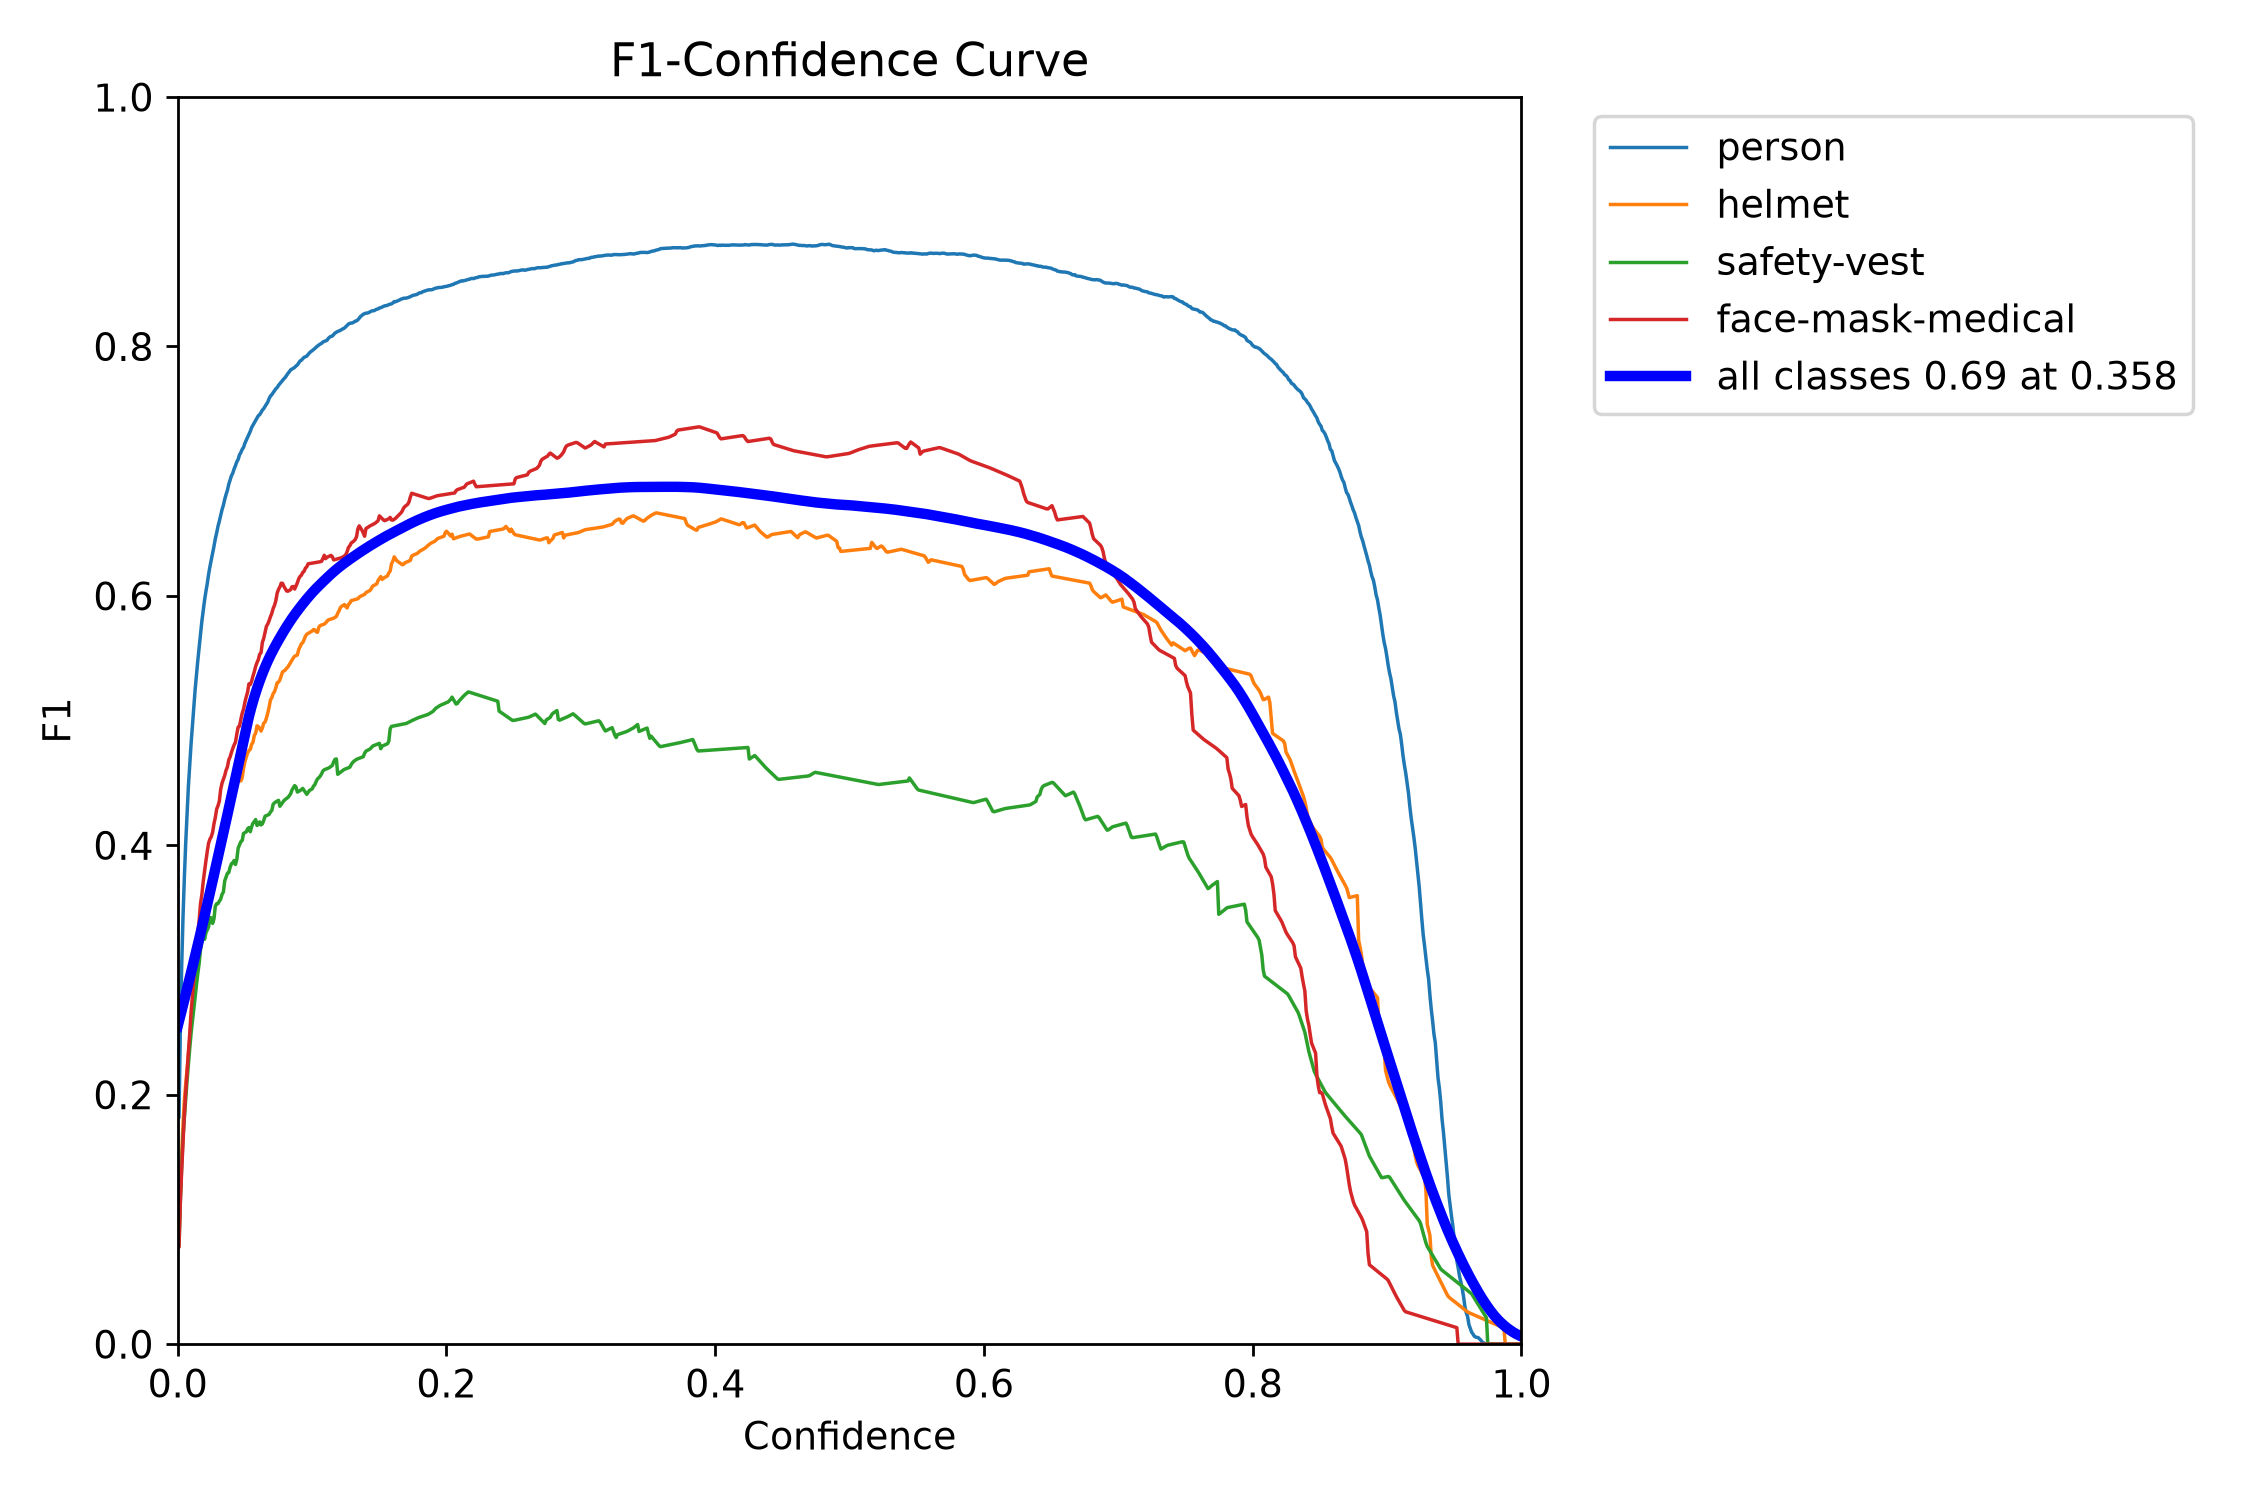

Precision versus confidence


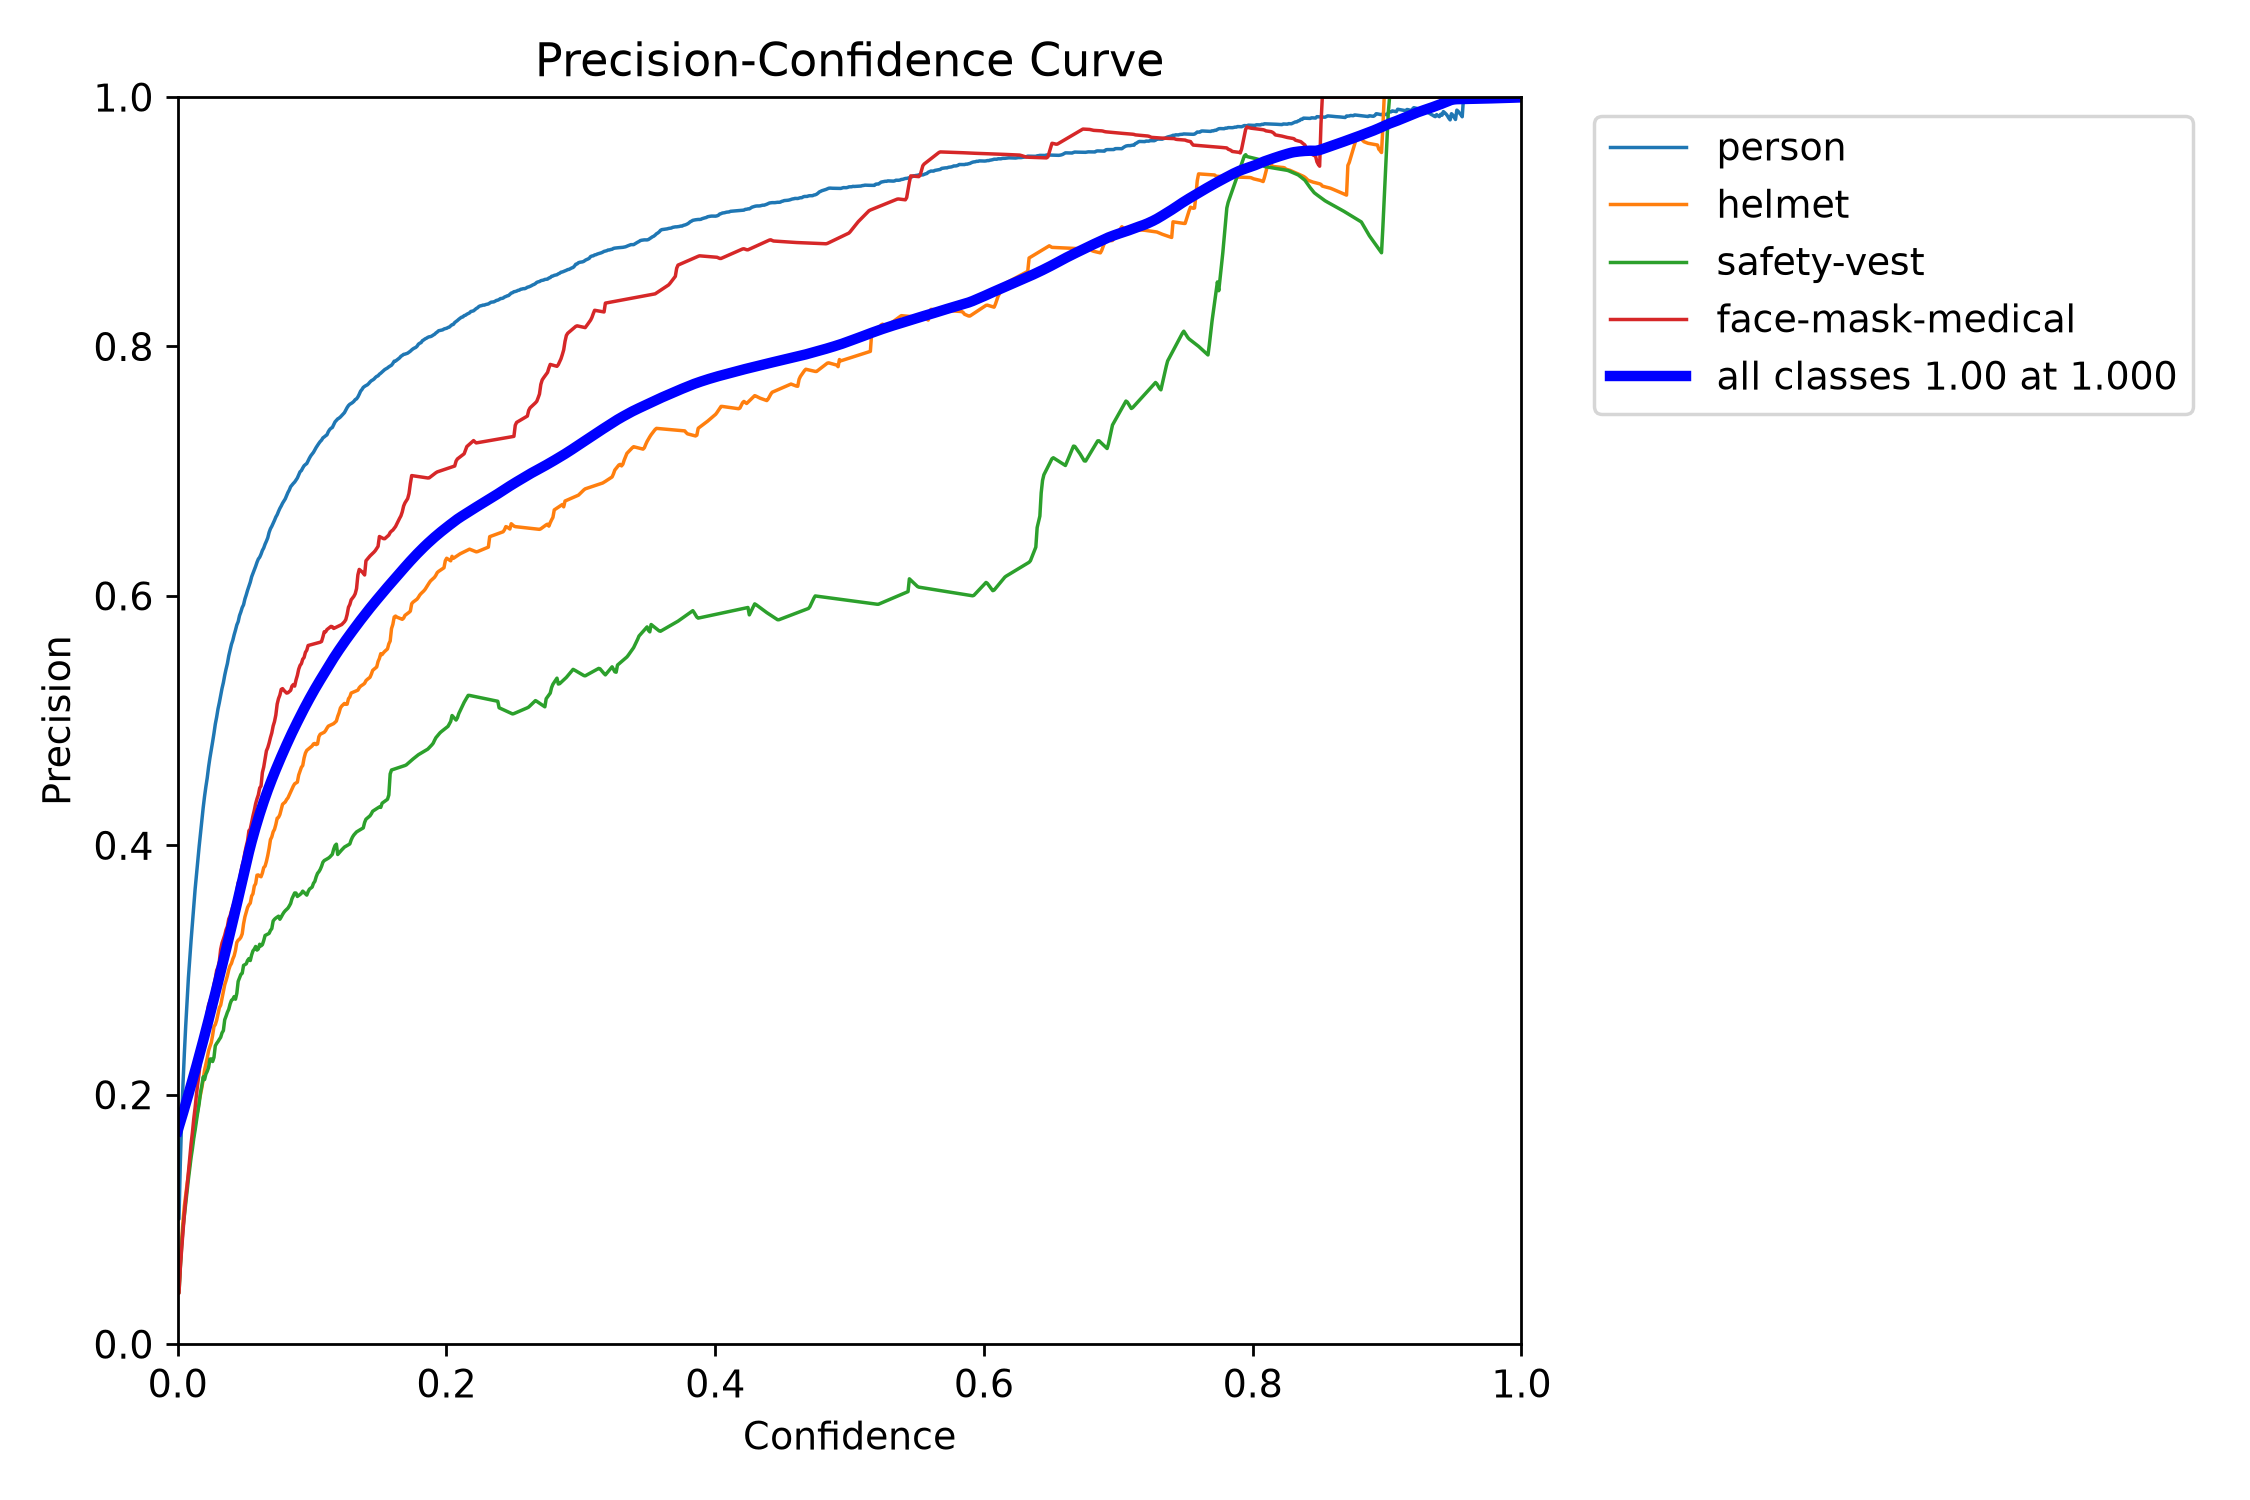

Recall versus confidence


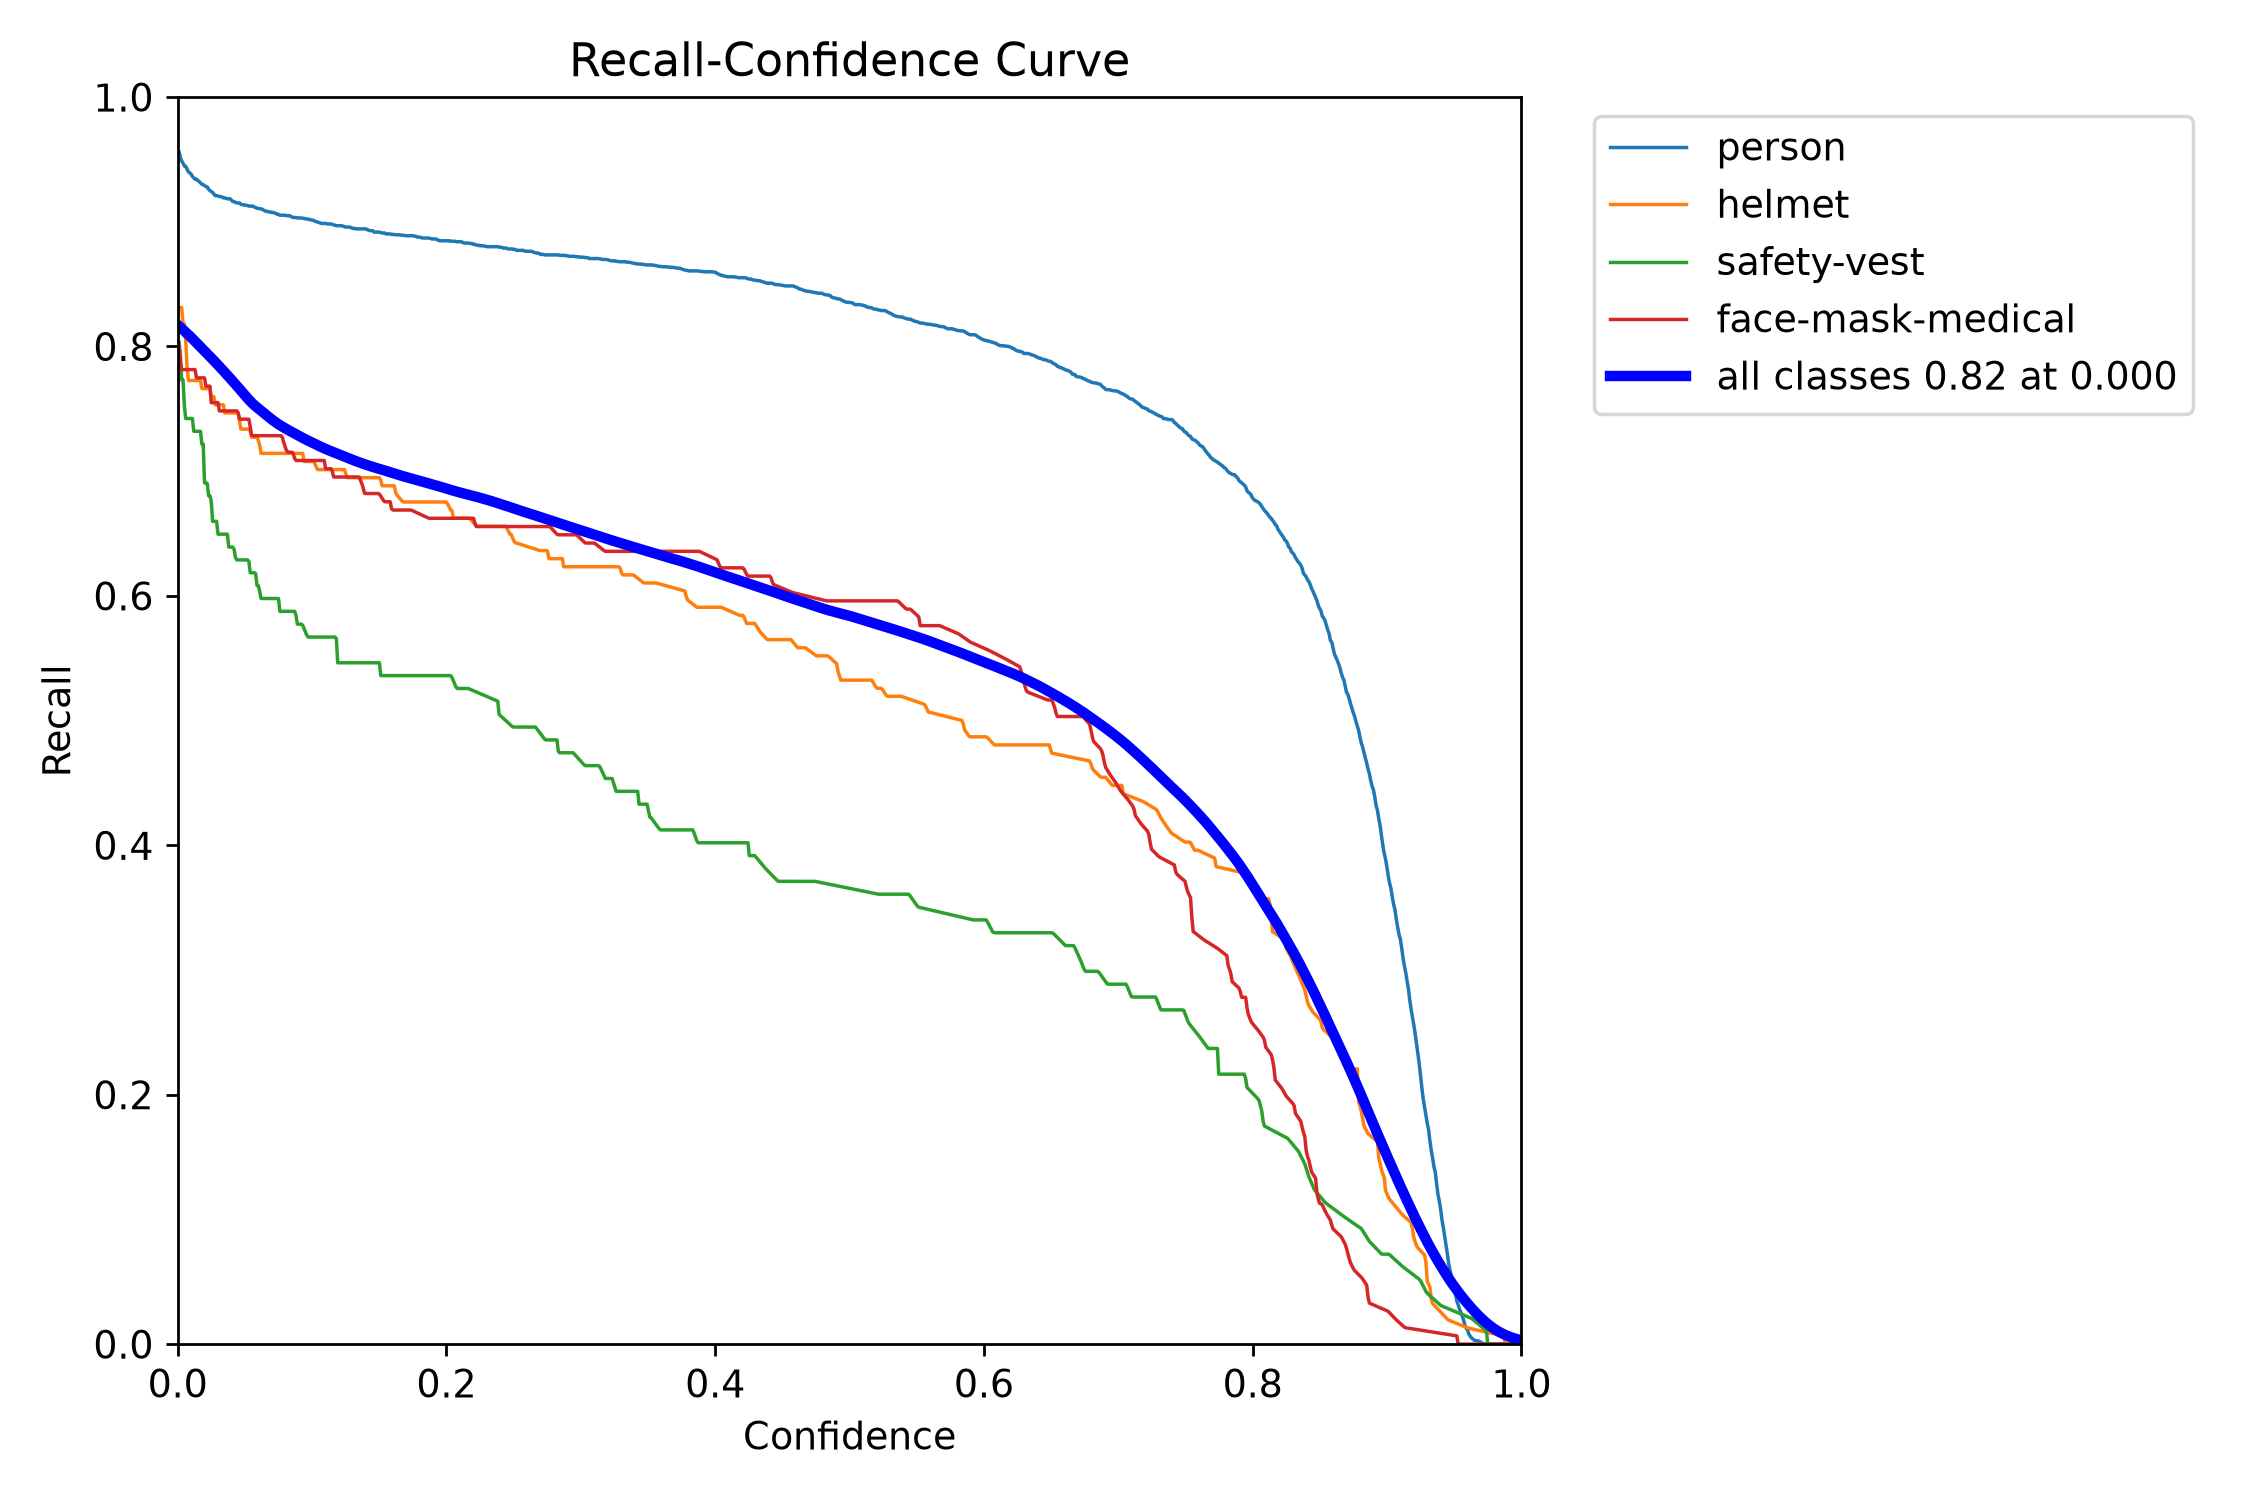

In [11]:
confidence_curve_paths = {
    "F1 versus confidence": Path(metrics.save_dir) / "BoxF1_curve.png",
    "Precision versus confidence": Path(metrics.save_dir) / "BoxP_curve.png",
    "Recall versus confidence": Path(metrics.save_dir) / "BoxR_curve.png",
}

missing_curves = [path for path in confidence_curve_paths.values() if not path.is_file()]
if missing_curves:
    raise FileNotFoundError(
        "Missing confidence-curve output(s):\n"
        + "\n".join(f"- {path}" for path in missing_curves)
    )

for title, path in confidence_curve_paths.items():
    print(title)
    with PILImage.open(path) as image:
        display(image.copy())

### Confidence-curve interpretation

The class curves peak at different confidence levels, so one global threshold cannot optimize every class simultaneously. Safety vest remains the lowest-F1 class across the useful threshold range. Person tolerates a higher threshold while preserving strong recall, whereas aggressive thresholding quickly removes many vest and mask detections.

The precision curve reaching `1.00` near confidence `1.0` is not evidence of a perfect detector—almost no predictions survive at that extreme. Likewise, recall is highest near confidence zero because almost every candidate is retained, including many false positives. A threshold must be judged using both error types and the application's costs.

For now, `0.358` is recorded as the validation-set mean-F1 reference. Threshold calibration should be repeated after selecting the final model, and the eventual compliance system may justify class-specific thresholds.

## 9. Run Python-API inference on unseen images

The 10 unseen images test behavior outside the labeled validation split. Because they have no ground-truth YOLO labels, they support **qualitative failure analysis only**; they cannot produce valid precision, recall, or mAP.

We use confidence `0.25` as a consistent inspection threshold, not as the final deployment choice. `save=False` keeps results in memory and avoids the nested Ultralytics output-directory issue. Each returned `Results` object contains the original image, predicted boxes, class IDs, confidences, timing, and plotting helpers.

Ultralytics may assign generic values such as `image0.jpg` to `Result.path` for a mixed-format source list. We therefore pair the returned results with our original sorted paths using `zip`, preserving the real filenames.

In [12]:
INFERENCE_CONFIDENCE = 0.25
INFERENCE_IOU = 0.70
inference_image_paths = sorted(unseen_image_paths, key=lambda path: path.name.casefold())

inference_results = model.predict(
    source=[str(path) for path in inference_image_paths],
    imgsz=640,
    conf=INFERENCE_CONFIDENCE,
    iou=INFERENCE_IOU,
    device=DEVICE,
    save=False,
    verbose=False,
)

if len(inference_results) != len(inference_image_paths):
    raise RuntimeError(
        f"Expected {len(inference_image_paths)} results, "
        f"received {len(inference_results)}"
    )

print(f"Images processed: {len(inference_results)}")
print(f"Inspection confidence: {INFERENCE_CONFIDENCE}")
print(f"NMS IoU threshold: {INFERENCE_IOU}")

Images processed: 10
Inspection confidence: 0.25
NMS IoU threshold: 0.7


### Convert predictions into analyzable data

`result.boxes` stores tensors for class IDs, confidence scores, and `xyxy` pixel coordinates. Moving those tensors to CPU and converting them into records gives us a normal DataFrame that can be filtered and summarized.

Prediction counts are **not correctness counts**. For example, three vest predictions could mean three correct vests, duplicated boxes on one vest, or a false positive on similar clothing. Human inspection is still required because these images are unlabeled.

In [13]:
detection_records = []
for source_path, result in zip(inference_image_paths, inference_results):
    image_height, image_width = result.orig_shape
    class_ids = result.boxes.cls.cpu().tolist()
    confidences = result.boxes.conf.cpu().tolist()
    boxes_xyxy = result.boxes.xyxy.cpu().tolist()

    for class_id, confidence, (x1, y1, x2, y2) in zip(
        class_ids, confidences, boxes_xyxy
    ):
        relative_box_area = (
            (x2 - x1) * (y2 - y1) / (image_width * image_height)
        )
        detection_records.append(
            {
                "Image": source_path.name,
                "Class": model.names[int(class_id)],
                "Confidence": float(confidence),
                "x1": float(x1),
                "y1": float(y1),
                "x2": float(x2),
                "y2": float(y2),
                "Box area %": float(relative_box_area * 100),
            }
        )

detections_df = pd.DataFrame(detection_records)
prediction_counts = (
    detections_df.groupby(["Image", "Class"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=[path.name for path in inference_image_paths], fill_value=0)
    .reindex(columns=EXPECTED_CLASS_NAMES, fill_value=0)
)
prediction_counts["Total"] = prediction_counts.sum(axis=1)
prediction_counts

Class,person,helmet,safety-vest,face-mask-medical,Total
Image,,,,,
2076756-1175839643.jpeg,7,0,0,5,12
960x0.webp,1,0,0,0,1
how-to-be-a-people-person-1662995088.jpg,5,0,0,0,5
images (1).jpeg,6,1,1,0,8
images.jpeg,1,0,0,1,2
people.jpg,145,0,0,0,145
Personal-Protective-EquipmentPPE-scaled.jpg,5,5,3,0,13
pexels-photo-8487396.webp,1,0,1,0,2
Rafting_PPE.webp,4,3,0,0,7


In [14]:
confidence_summary = (
    detections_df.groupby("Class")["Confidence"]
    .agg(Detections="count", Mean="mean", Minimum="min", Maximum="max")
    .reindex(EXPECTED_CLASS_NAMES)
)
confidence_summary.style.format(
    {"Mean": "{:.3f}", "Minimum": "{:.3f}", "Maximum": "{:.3f}"},
    na_rep="—",
)

,Detections,Mean,Minimum,Maximum
Class,,,,
person,184,0.512,0.251,0.942
helmet,9,0.728,0.274,0.888
safety-vest,5,0.598,0.418,0.742
face-mask-medical,6,0.666,0.447,0.926


### Display predictions in the notebook

`result.plot()` draws labels, confidence scores, and boxes onto a copy of the source image. Ultralytics returns the plotted array in OpenCV's BGR channel order, while Matplotlib expects RGB, so `[..., ::-1]` reverses the channel order before display.

In [15]:
import matplotlib.pyplot as plt

plot_columns = 2
plot_rows = (len(inference_results) + plot_columns - 1) // plot_columns
figure, axes = plt.subplots(plot_rows, plot_columns, figsize=(16, 5 * plot_rows))
axes = np.atleast_1d(axes).ravel()

for axis, source_path, result in zip(axes, inference_image_paths, inference_results):
    annotated_bgr = result.plot(labels=True, conf=True, line_width=2)
    axis.imshow(annotated_bgr[..., ::-1])
    axis.set_title(source_path.name)
    axis.axis("off")

for unused_axis in axes[len(inference_results):]:
    unused_axis.axis("off")

figure.suptitle(
    f"Unseen-image predictions at confidence ≥ {INFERENCE_CONFIDENCE}",
    fontsize=16,
)
figure.tight_layout()
plt.show()

<Figure size 1600x2500 with 10 Axes>

## 10. Qualitative failure analysis

These observations come from the Python-API predictions at confidence `0.25` and visual inspection of all 10 images. Because the images are unlabeled, terms such as *apparent miss* or *likely false positive* represent human review rather than formally measured errors.

### Strengths observed

- Person detection is reliable in clear, ordinary group scenes. The five people in `how-to-be-a-people-person-1662995088.jpg` are detected without spurious PPE predictions.
- Clear, frontal medical masks can receive strong confidence. `images.jpeg` produces one person and one mask prediction, both above `0.89`.
- The industrial group in `Personal-Protective-EquipmentPPE-scaled.jpg` produces five person and five helmet detections, with helmet confidences roughly `0.82–0.89`.
- All three rafting helmets are detected in `Rafting_PPE.webp`, showing some generalization beyond construction-style hard hats.
- The model detects very small people in `people.jpg`, demonstrating useful multi-scale person sensitivity.

### Weaknesses and failure patterns observed

- **Mask recall is inconsistent:** `960x0.webp` contains a clear close-up face covering but produces only a person prediction. In the seven-person clinical group, only five mask predictions survive at confidence `0.25`.
- **Vest appearance is ambiguous:** in the industrial group, three vest predictions are produced although only two workers wear visually clear green high-visibility vests. Orange reflective coveralls appear capable of triggering a vest-like prediction.
- **Unusual pose can cause duplicate people:** `Rafting_PPE.webp` contains three visible rafters but produces four person boxes, including overlapping coverage of the central subject.
- **Heavy occlusion and partial bodies remain difficult:** `trevor-cole-CWcAsKuhwy0-unsplash+copy.webp` contains many overlapping people but only nine person detections, several at low confidence.
- **Dense scenes become visually noisy:** `people.jpg` produces 145 person boxes. Without labels we cannot calculate its accuracy, but the crowded output shows why later real-time displays will need careful confidence and rendering choices.
- PPE that is held, lying on a table, partly cropped, or used outside the training context behaves inconsistently. This suggests the model has learned both object appearance and contextual cues such as PPE being worn on a person.

The 10-image set is deliberately varied but too small and too informal for statistical conclusions. It is useful for generating hypotheses that must be tested on labeled validation examples.

## 11. Baseline strengths and weaknesses

### Strengths

- Strong person detection: precision `0.892`, recall `0.864`, and mAP50–95 `0.713`.
- Helmet and face-mask detections are often precise when the object is clear.
- Training converged normally without obvious severe overfitting.
- The small YOLOv8n model evaluates quickly on the RTX 5050, making it a sensible real-time baseline.
- Helmet generalization to the rafting scene and clean behavior on a non-PPE group image are encouraging.

### Weaknesses

- Safety vest is recall-limited: recall `0.413`, mAP50 `0.478`, and mAP50–95 `0.280`.
- Nearly half of true vests represented in the normalized confusion matrix fall into the background row.
- Face mask has the largest mAP50-to-mAP50–95 gap (`0.323`), indicating weak tight-box localization despite reasonable AP50.
- PPE performance changes substantially with appearance, context, occlusion, and cropping.
- One global confidence threshold cannot optimize person, helmet, vest, and mask simultaneously.
- The weak classes have few validation images and instances, making their estimates less stable and reducing coverage of visual variation.

## 12. Evidence-based recommendations for Phase 6

The baseline remains immutable. Each experiment should change one major variable and report overall **and per-class** metrics, plus latency and VRAM when model size or image size changes.

### Recommended order

1. **Audit weak-class examples before retraining.** On the labeled validation set, compare object-size distributions by class and inspect matched versus missed vest/mask boxes. Review annotation consistency, occlusion, cropping, viewpoints, lighting, and whether `safety-vest` is defined consistently for reflective coveralls.
2. **Correct or extend the dataset only if the audit supports it.** Prioritize diverse, correctly labeled safety-vest and face-mask examples rather than simply duplicating existing images. Preserve the current validation split so comparisons remain meaningful; ideally reserve a future independent test set.
3. **Test image resolution as a controlled experiment if misses are small-object dominated.** Compare YOLOv8n at `640` with one higher resolution while keeping the dataset, epochs, seed, and other settings fixed. Measure weak-class gains against inference latency and VRAM.
4. **Test model capacity separately.** Compare YOLOv8n with YOLOv8s at the same resolution and training configuration. A larger model is worthwhile only if per-class improvements justify its real-time cost.
5. **Use failure-specific augmentation, not random tuning.** If the audit confirms occlusion, scale, or lighting failures, change one relevant augmentation policy and document the hypothesis. Avoid changing resolution, model size, augmentation, and epochs together.
6. **Treat longer training as a lower-priority experiment.** The baseline curves already converged normally, so extra epochs have weaker evidence than the dataset and weak-class issues above. Use early stopping and compare the same metrics if tested.
7. **Calibrate confidence after model selection.** Evaluate global versus class-specific thresholds based on compliance-system costs. Lowering the vest threshold may improve recall but does not improve AP and may create unacceptable false alarms.

### Success criteria

A Phase 6 candidate should not be accepted solely because overall mAP increases. It should improve or preserve safety-vest recall/mAP, improve mask localization where possible, avoid material regression in person/helmet performance, and maintain a practical latency/FPS/VRAM profile.

## 13. Phase 5 conclusion

The YOLOv8n checkpoint is a successful baseline, not a finished PPE compliance model. Person detection is strong, helmet and mask performance are usable but inconsistent on harder appearances, and safety vest is the principal detection weakness. The validation matrix shows that vest misses are more important than cross-class confusion, while unseen images expose contextual, occlusion, duplicate-box, and appearance-related failures.

Phase 5 is complete when this notebook has been run top-to-bottom and its outputs reviewed. Phase 6 should begin with a targeted weak-class/data audit and controlled experiment design—not immediate broad hyperparameter tuning.